# Rodízio de assinaturas de streaming
### Quais plataformas assinar em cada mês para ver tudo gastando o mínimo?

**COS360 / COM361 – Otimização** · Projeto final
Técnicas usadas: **cobertura de conjuntos** (aula 21) + **custo fixo** (aula 19) + **limite de horas por mês** (restrição de capacidade), resolvidas como um **Programa Linear Inteiro Misto (MILP)**.

> ⚠️ **Sobre os dados:** os preços e as datas de disponibilidade deste notebook são **ilustrativos** (valores aproximados em R$).

## 1. Introdução

### O problema do dia a dia
Hoje o conteúdo de que gostamos está espalhado por várias plataformas: Netflix, Max, Prime Video, Disney+, Globoplay, Apple TV... Assinar todas ao mesmo tempo, o ano inteiro, sai caro. Mas uma assinatura de streaming **normalmente não tem fidelidade**: dá para assinar num mês, cancelar no seguinte e voltar depois. Quem faz isso de propósito é chamado, informalmente, de quem pratica o *rodízio de assinaturas* (em inglês, *subscription cycling* ou *churning*).

A pergunta é: **dada a minha lista de séries e filmes, e sabendo em qual plataforma cada um está e a partir de quando, em quais meses devo assinar quais plataformas para ver tudo pagando o mínimo?**

Não é trivial, porque as decisões interagem:
- Se eu assinar a Netflix em março, posso aproveitar para ver *todos* os títulos dela de uma vez, mas só consigo ver um número limitado de horas por mês.
- Um título que só estreia em agosto não pode ser visto antes.
- Alguns combos (por exemplo, Prime + Apple TV) custam menos que as duas assinaturas separadas.

O problema tem a estrutura de dois problemas clássicos de Pesquisa Operacional:

- **Cobertura de conjuntos (*set cover*).** Dado um universo de elementos e uma coleção de subconjuntos com custos, escolher os subconjuntos mais baratos que cobrem todos os elementos. Foi um dos 21 problemas NP-completos de Karp (1972). Tem aplicações clássicas como localização de serviços de emergência (Toregas et al., 1971) e escalonamento de tripulações aéreas (Hoffman & Padberg, 1993). Chvátal (1979) analisou a heurística gulosa para ele.
- **Custo fixo (*fixed-charge*).** Pagar uma taxa fixa para "ativar" uma opção, independentemente de quanto ela é usada. Foi estudado por Hirsch & Dantzig (1968). Aqui a taxa fixa é a mensalidade: pagamos o mesmo preço vendo 1 hora ou 30 horas.

Nosso problema junta os dois e adiciona o **tempo** (12 meses) e um **limite de horas de tela por mês**.

## 2. Modelo matemático

### 2.1 Conjuntos e dados

| Símbolo | Significado |
|---|---|
| $T$ | conjunto de títulos que quero ver (séries/filmes) |
| $M = \{1,\dots,12\}$ | meses |
| $K$ | conjunto de **ofertas** que posso comprar num mês (um plano de uma plataforma, com ou sem anúncios, ou um combo) |
| $c_k$ | preço mensal da oferta $k$ |
| $h_t$ | horas necessárias para ver o título $t$ inteiro |
| $P_t$ | plataformas em que o título $t$ está disponível |
| $[a_t, b_t]$ | janela de disponibilidade: o título pode ser visto do mês $a_t$ (estreia) até o mês $b_t$ (quando sai do catálogo) |
| $H$ | limite de horas de tela por mês |
| $\text{cob}_{t,k}$ | $=1$ se a oferta $k$ dá acesso a alguma plataforma de $P_t$, $0$ caso contrário |

### 2.2 Variáveis de decisão

$$y_{k,m} = \begin{cases}1 & \text{se assino a oferta } k \text{ no mês } m\\ 0 & \text{caso contrário}\end{cases}
\qquad
x_{t,m} = \begin{cases}1 & \text{se vejo o título } t \text{ no mês } m\\ 0 & \text{caso contrário}\end{cases}$$

### 2.3 Modelo completo

$$
\begin{aligned}
\min \quad & \sum_{k\in K}\sum_{m\in M} c_k\, y_{k,m} && \text{(custo total das assinaturas)}\\[4pt]
\text{s.a.}\quad & \sum_{m\in M} x_{t,m} = 1 && \forall t\in T \quad \text{(cada título é visto exatamente uma vez)}\\
& \sum_{t\in T} h_t\, x_{t,m} \le H && \forall m\in M \quad \text{(limite de horas no mês)}\\
& x_{t,m} \le \sum_{k:\ \text{cob}_{t,k}=1} y_{k,m} && \forall t\in T,\ m\in M \quad \text{(só vejo se tenho acesso)}\\
& x_{t,m} = 0 && \forall t,\ m\notin[a_t,b_t] \quad \text{(janela de disponibilidade)}\\
& x_{t,m},\, y_{k,m}\in\{0,1\}
\end{aligned}
$$

### 2.4 De onde vêm as ideias do modelo

- **Cobertura de conjuntos:** cada título precisa ser "coberto" por alguma assinatura ativa no mês em que é visto. É a restrição $x_{t,m}\le\sum y_{k,m}$.
- **Custo fixo:** pagamos $c_k$ ao ligar $y_{k,m}=1$, não importa quantas horas assistimos. Por isso a função objetivo só depende dos $y$, e os $x$ só aparecem nas restrições. Os $y$ "ligam" os $x$.
- **Capacidade:** o limite $H$ evita a solução absurda de ver 150 horas num único mês. Sem ele, o ótimo seria assinar cada plataforma uma única vez.

> Poderíamos escrever uma restrição só por mês ("$\sum_t x_{t,m} \le |T|\cdot y_{k,m}$"), mas essa versão é mais fraca: o relaxamento linear fica longe do inteiro e o solver demora mais. A versão desagregada acima é a forma padrão em problemas de custo fixo (Wolsey, 1998).

### 2.5 Aproximações e hipóteses (o que estamos ignorando)

1. **Preços constantes no ano** (sem promoções, reajustes ou meses grátis).
2. **Sem custo de troca:** cancelar e reassinar é gratuito e imediato. Na prática, algumas plataformas cobram até o fim do ciclo, mas assumimos que a assinatura vale por mês fechado.
3. **O tempo de cada título é conhecido** ($h_t$ = duração total) e **cada título é visto em um único mês**. Na seção 5 relaxamos isso.
4. **Planos com anúncios dão acesso ao mesmo catálogo** (na prática, o plano com anúncios pode ter restrições, mas só mudamos o preço e tratamos o custo "incômodo" na discussão).
5. **Disponibilidade conhecida:** assumimos que o catálogo não muda de surpresa.
6. **Todas as horas valem igual:** ignoramos que vejo mais nos fins de semana, em férias etc.


## 3. Solução

Resolvemos com `scipy.optimize.milp`, que usa o solver **HiGHS** (Huangfu & Hall, 2018). Primeiro um exemplo pequeno que dá para conferir à mão e por força bruta; depois a instância completa.

### 3.1 Funções auxiliares

In [1]:
import itertools
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

In [2]:
def resolver(titulos, ofertas, meses, horas_max, dividir=False, relaxar=False, cortes=True, limite_tempo=60):
    """
    Monta e resolve o MILP da seção 2.3.

    titulos   : DataFrame com colunas nome, plataformas (frozenset), lanca, sai, horas, quem
    ofertas   : DataFrame com colunas nome, plataformas (frozenset), preco
    meses     : lista de meses (ex.: [1, ..., 12])
    horas_max : limite de horas por mês (número, ou dict {pessoa: limite})
    dividir   : se True, permite dividir um título entre meses (x vira contínuo em [0,1])
    relaxar   : se True, tira a integralidade de tudo (relaxamento linear, só para estudo)
    cortes    : se True, acrescenta cortes de capacidade (seção 4.1): não mudam o ótimo, só aceleram

    Retorna um dict com 'custo', 'y' (K x M) e 'x' (T x M), ou None se for inviável.
    """
    titulos = titulos.reset_index(drop=True)
    ofertas = ofertas.reset_index(drop=True)
    T, K, M = len(titulos), len(ofertas), len(meses)

    # Posição de cada variável no vetor de decisão: primeiro todos os y, depois todos os x
    iy = lambda k, m: k * M + m
    ix = lambda t, m: K * M + t * M + m
    n = K * M + T * M

    # --- Função objetivo: só os y têm custo (mensalidade) ---
    c = np.zeros(n)
    for k in range(K):
        for m in range(M):
            c[iy(k, m)] = ofertas.loc[k, "preco"]

    donos = sorted(titulos["quem"].unique())
    H = horas_max if isinstance(horas_max, dict) else {d: horas_max for d in donos}

    # --- Restrições (A x entre lb e ub) ---
    plats = sorted(set().union(*titulos["plataformas"]))
    nlin = T + len(donos) * M + T * M + len(plats)
    A = lil_matrix((nlin, n))
    lb = np.full(nlin, -np.inf)
    ub = np.zeros(nlin)
    r = 0

    # (1) cada título é visto exatamente uma vez:  sum_m x[t,m] = 1
    for t in range(T):
        for m in range(M):
            A[r, ix(t, m)] = 1
        lb[r] = ub[r] = 1
        r += 1

    # (2) limite de horas por pessoa e por mês:  sum_t h_t x[t,m] <= H
    for d in donos:
        for m in range(M):
            for t in range(T):
                if titulos.loc[t, "quem"] == d:
                    A[r, ix(t, m)] = titulos.loc[t, "horas"]
            ub[r] = H[d]
            r += 1

    # (3) só vejo se tenho acesso:  x[t,m] - sum_{k que cobre t} y[k,m] <= 0
    for t in range(T):
        for m in range(M):
            A[r, ix(t, m)] = 1
            for k in range(K):
                if ofertas.loc[k, "plataformas"] & titulos.loc[t, "plataformas"]:
                    A[r, iy(k, m)] = -1
            ub[r] = 0
            r += 1

    # (4) cortes de capacidade (opcionais): se uma plataforma tem H_p horas de títulos exclusivos
    #     e só dá para ver 'cap' horas por mês, ela precisa estar ativa em pelo menos ceil(H_p/cap) meses
    if cortes:
        cap = sum(H[d] for d in donos)
        for p in plats:
            h_p = titulos.loc[titulos["plataformas"] == frozenset({p}), "horas"].sum()
            n_min = int(np.ceil(h_p / cap - 1e-9))
            if n_min >= 1:
                for k in range(K):
                    if p in ofertas.loc[k, "plataformas"]:
                        for m in range(M):
                            A[r, iy(k, m)] = 1
                lb[r], ub[r] = n_min, np.inf
                r += 1

    # --- Limites das variáveis: janela de disponibilidade fixa x[t,m] = 0 fora dela ---
    ubv = np.ones(n)
    for t in range(T):
        for m in range(M):
            if meses[m] < titulos.loc[t, "lanca"] or meses[m] > titulos.loc[t, "sai"]:
                ubv[ix(t, m)] = 0

    # --- Integralidade: y sempre binário; x binário, a menos que 'dividir' ---
    integ = np.zeros(n)
    if not relaxar:
        integ[:K * M] = 1
        if not dividir:
            integ[K * M:] = 1

    res = milp(c, constraints=LinearConstraint(A.tocsr(), lb, ub), bounds=Bounds(0, ubv),
               integrality=integ, options={"time_limit": limite_tempo})
    if res.x is None:
        return None
    return {"custo": res.fun,
            "y": res.x[:K * M].reshape(K, M),
            "x": res.x[K * M:].reshape(T, M)}


def mostrar(res, titulos, ofertas, meses, rotulos=MESES):
    """Imprime o plano: o que assinar em cada mês e o que assistir."""
    titulos, ofertas = titulos.reset_index(drop=True), ofertas.reset_index(drop=True)
    print(f"CUSTO TOTAL: R$ {res['custo']:.2f}\n")
    for m in range(len(meses)):
        planos = [ofertas.loc[k, "nome"] for k in range(len(ofertas)) if res["y"][k, m] > 0.5]
        if not planos:
            continue
        vistos = [f"{titulos.loc[t, 'nome']} ({titulos.loc[t, 'horas'] * res['x'][t, m]:.0f}h)"
                  for t in range(len(titulos)) if res["x"][t, m] > 1e-6]
        print(f"{rotulos[meses[m] - 1]}: assinar {' + '.join(planos)}")
        print(f"      assistir: {', '.join(vistos)}")

In [3]:
def construir_cobertura(ofertas):
    """
    Devolve uma função f(conjunto de plataformas) = menor custo mensal de comprar ofertas
    (planos/combos) que dêem acesso a todas elas. Força bruta: há poucas ofertas.
    """
    ofs = list(zip(ofertas["plataformas"], ofertas["preco"]))

    @lru_cache(maxsize=None)
    def f(necessarias):
        if not necessarias:
            return 0.0
        melhor = np.inf
        for r in range(1, len(ofs) + 1):
            for comb in itertools.combinations(range(len(ofs)), r):
                coberto = set().union(*[ofs[i][0] for i in comb])
                if necessarias <= coberto:
                    melhor = min(melhor, sum(ofs[i][1] for i in comb))
        return melhor
    return f


def forca_bruta(titulos, ofertas, meses, H):
    """Verificação independente (só para o exemplo pequeno): testa TODAS as formas de
    escolher o mês de cada título e, para cada uma, paga a cobertura mais barata."""
    cob = construir_cobertura(ofertas)
    janelas = [[m for m in meses if r.lanca <= m <= r.sai] for r in titulos.itertuples()]
    melhor, melhor_atrib = np.inf, None
    for atrib in itertools.product(*janelas):
        horas = {m: 0 for m in meses}
        for h, m in zip(titulos["horas"], atrib):
            horas[m] += h
        if any(v > H + 1e-9 for v in horas.values()):
            continue
        custo = sum(cob(frozenset().union(*[p for p, a in zip(titulos["plataformas"], atrib) if a == m]))
                    for m in meses)
        if custo < melhor:
            melhor, melhor_atrib = custo, atrib
    return melhor, melhor_atrib


def baseline_ingenuo(titulos, ofertas, meses, H):
    """Estratégia 'assistir assim que lançar': cada título vai para o primeiro mês disponível
    em que ainda cabe nas horas; depois paga-se a cobertura mais barata de cada mês."""
    cob = construir_cobertura(ofertas)
    usado = {m: 0 for m in meses}
    por_mes = {m: set() for m in meses}
    for r in titulos.sort_values("lanca").itertuples():
        for m in meses:
            if r.lanca <= m <= r.sai and usado[m] + r.horas <= H:
                usado[m] += r.horas
                por_mes[m].add(sorted(r.plataformas)[0])
                break
    return sum(cob(frozenset(s)) for s in por_mes.values())


def calendario(res, titulos, ofertas, meses, plataformas, titulo=""):
    """Mapa plataformas x meses: azul = assinatura ativa; número = horas assistidas ali."""
    titulos, ofertas = titulos.reset_index(drop=True), ofertas.reset_index(drop=True)
    P, M = len(plataformas), len(meses)
    ativo, horas = np.zeros((P, M)), np.zeros((P, M))
    for k in range(len(ofertas)):
        for m in range(M):
            if res["y"][k, m] > 0.5:
                for p in ofertas.loc[k, "plataformas"]:
                    ativo[plataformas.index(p), m] = 1
    for t in range(len(titulos)):
        for m in range(M):
            if res["x"][t, m] > 1e-6:
                for p in sorted(titulos.loc[t, "plataformas"]):
                    if ativo[plataformas.index(p), m]:
                        horas[plataformas.index(p), m] += titulos.loc[t, "horas"] * res["x"][t, m]
                        break
    fig, ax = plt.subplots(figsize=(1 + 0.75 * M, 0.6 + 0.55 * P))
    ax.imshow(ativo, cmap="Blues", vmin=0, vmax=1.7, aspect="auto")
    for p in range(P):
        for m in range(M):
            if horas[p, m] > 0:
                ax.text(m, p, f"{horas[p, m]:.0f}h", ha="center", va="center", fontsize=9, color="white" if ativo[p, m] else "black", fontweight="bold")
    ax.set_xticks(range(M)); ax.set_xticklabels([MESES[m - 1] for m in meses])
    ax.set_yticks(range(P)); ax.set_yticklabels(plataformas)
    ax.set_title(f"{titulo}   (azul = assinatura ativa, número = horas assistidas)", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
    plt.tight_layout(); plt.show()

### 3.2 Exemplo pequeno: 3 plataformas, 6 títulos, 3 meses

Começamos com um caso que dá para resolver "na cabeça": limite de **20 h/mês** e um plano por plataforma. Cada título tem uma plataforma e um mês de estreia.

In [4]:
F = frozenset

# Cada oferta: nome, plataformas a que dá acesso, preço mensal (R$)
ofertas_peq = pd.DataFrame([
    ("Netflix",     F({"Netflix"}),     44.90),
    ("Max",         F({"Max"}),         29.90),
    ("Prime Video", F({"Prime Video"}), 19.90),
], columns=["nome", "plataformas", "preco"])

# Cada título: nome, plataformas, mês de estreia, último mês disponível, horas, quem vai ver
titulos_peq = pd.DataFrame([
    ("Stranger Things T5", F({"Netflix"}),     1, 3, 10, "Eu"),
    ("Adolescence",        F({"Netflix"}),     2, 3,  4, "Eu"),
    ("The Last of Us T2",  F({"Max"}),         1, 3,  8, "Eu"),
    ("Succession T4",      F({"Max"}),         2, 3, 10, "Eu"),
    ("The Boys T5",        F({"Prime Video"}), 2, 3,  8, "Eu"),
    ("Fallout T2",         F({"Prime Video"}), 3, 3,  8, "Eu"),
], columns=["nome", "plataformas", "lanca", "sai", "horas", "quem"])

display(titulos_peq.assign(plataformas=titulos_peq["plataformas"].apply(lambda s: ", ".join(s))))
print(f"Total de horas: {titulos_peq['horas'].sum()}h  |  capacidade em 3 meses: {3*20}h")

,nome,plataformas,lanca,sai,horas,quem
0,Stranger Things T5,Netflix,1,3,10,Eu
1,Adolescence,Netflix,2,3,4,Eu
2,The Last of Us T2,Max,1,3,8,Eu
3,Succession T4,Max,2,3,10,Eu
4,The Boys T5,Prime Video,2,3,8,Eu
5,Fallout T2,Prime Video,3,3,8,Eu


Total de horas: 48h  |  capacidade em 3 meses: 60h


CUSTO TOTAL: R$ 139.60

Jan: assinar Netflix
      assistir: Stranger Things T5 (10h)
Fev: assinar Max
      assistir: The Last of Us T2 (8h), Succession T4 (10h)
Mar: assinar Netflix + Prime Video
      assistir: Adolescence (4h), The Boys T5 (8h), Fallout T2 (8h)


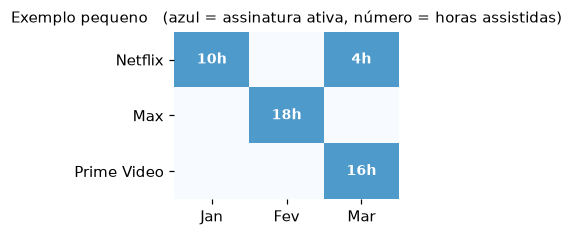

In [5]:
meses_peq, H_peq = [1, 2, 3], 20
res_peq = resolver(titulos_peq, ofertas_peq, meses_peq, H_peq)
mostrar(res_peq, titulos_peq, ofertas_peq, meses_peq)
calendario(res_peq, titulos_peq, ofertas_peq, meses_peq, ["Netflix", "Max", "Prime Video"], "Exemplo pequeno")

**Conferência por força bruta.** Como são só 6 títulos e 3 meses, dá para testar *todas* as $3^6$ formas de escolher o mês de cada título e conferir se o MILP achou mesmo o mínimo:

In [6]:
custo_fb, atrib_fb = forca_bruta(titulos_peq, ofertas_peq, meses_peq, H_peq)
print(f"Força bruta (testando todas as atribuições): R$ {custo_fb:.2f}")
print(f"MILP:                                         R$ {res_peq['custo']:.2f}")
assert abs(custo_fb - res_peq["custo"]) < 1e-6, "O MILP e a força bruta deveriam coincidir!"
print("✔ Os dois coincidem.")

todas = sum(ofertas_peq["preco"]) * len(meses_peq)
print(f"\nPara comparar: assinar as 3 plataformas nos 3 meses custaria R$ {todas:.2f}")
print(f"Economia do plano ótimo: R$ {todas - res_peq['custo']:.2f} ({100*(1-res_peq['custo']/todas):.0f}%)")

Força bruta (testando todas as atribuições): R$ 139.60
MILP:                                         R$ 139.60
✔ Os dois coincidem.

Para comparar: assinar as 3 plataformas nos 3 meses custaria R$ 284.10
Economia do plano ótimo: R$ 144.50 (51%)


### 3.3 Instância completa: 6 plataformas, 12 meses, planos com anúncios e combos

Agora uma lista mais realista. As **ofertas** incluem o plano com anúncios de cada plataforma (mais barato), o plano sem anúncios e dois combos. Alguns títulos estão em mais de uma plataforma ("Filme Oscar") e alguns **saem do catálogo** antes do fim do ano.

> Lembrete: preços e datas são **ilustrativos**. Edite as duas tabelas abaixo com os seus dados reais.

In [7]:
PLATAFORMAS = ["Netflix", "Max", "Prime Video", "Disney+", "Globoplay", "Apple TV"]

# (nome, plataformas, preço mensal em R$, tem anúncios?)
_ofertas = [
    ("Netflix c/ anúncios",      {"Netflix"},                20.90, True),
    ("Netflix Padrão",           {"Netflix"},                44.90, False),
    ("Max c/ anúncios",          {"Max"},                    18.90, True),
    ("Max Padrão",               {"Max"},                    29.90, False),
    ("Prime Video",              {"Prime Video"},            19.90, False),
    ("Combo Prime + Apple TV",   {"Prime Video", "Apple TV"}, 34.90, False),
    ("Disney+ c/ anúncios",      {"Disney+"},                27.90, True),
    ("Disney+ Premium",          {"Disney+"},                43.90, False),
    ("Combo Disney+ + Max",      {"Disney+", "Max"},         49.90, False),
    ("Globoplay c/ anúncios",    {"Globoplay"},              24.90, True),
    ("Globoplay",                {"Globoplay"},              29.90, False),
    ("Apple TV",                 {"Apple TV"},               21.90, False),
]
ofertas = pd.DataFrame([(n, F(p), c, a) for n, p, c, a in _ofertas],
                       columns=["nome", "plataformas", "preco", "anuncios"])

# (nome, plataformas, mês de estreia, último mês disponível, horas, quem)
_titulos = [
    ("Stranger Things T5",     {"Netflix"},                 1, 12, 10),
    ("Adolescence",            {"Netflix"},                 1,  6,  4),
    ("Wednesday T2",           {"Netflix"},                 3, 12,  8),
    ("The Last of Us T2",      {"Max"},                     2, 12,  8),
    ("House of the Dragon T2", {"Max"},                     6, 12,  9),
    ("Succession T4",          {"Max"},                     1, 12, 10),
    ("The Boys T5",            {"Prime Video"},             4, 12,  8),
    ("Fallout T2",             {"Prime Video"},             7, 12,  8),
    ("Reacher T3",             {"Prime Video"},            10, 12,  8),
    ("Andor T2",               {"Disney+"},                 5, 12, 12),
    ("The Mandalorian T3",     {"Disney+"},                 8, 12,  8),
    ("Filme Pixar",            {"Disney+"},                11, 12,  2),
    ("Severance T2",           {"Apple TV"},                2, 12,  9),
    ("Ted Lasso T3",           {"Apple TV"},                9, 12,  8),
    ("Minissérie Globoplay",   {"Globoplay"},               6, 12,  6),
    ("Reality Globoplay",      {"Globoplay"},               1, 12, 12),
    ("Filme Oscar",            {"Netflix", "Prime Video"},  2,  8,  2),   # em duas plataformas
]
titulos = pd.DataFrame([(n, F(p), a, b, h, "Eu") for n, p, a, b, h in _titulos],
                       columns=["nome", "plataformas", "lanca", "sai", "horas", "quem"])

meses = list(range(1, 13))
H = 20  # horas de tela por mês

print(f"{len(titulos)} títulos, {titulos['horas'].sum()} horas no total (capacidade do ano: {12*H}h), {len(ofertas)} ofertas")
display(ofertas.assign(plataformas=ofertas["plataformas"].apply(lambda s: " + ".join(sorted(s)))))
display(titulos.drop(columns="quem").assign(plataformas=titulos["plataformas"].apply(lambda s: " ou ".join(sorted(s)))))

17 títulos, 132 horas no total (capacidade do ano: 240h), 12 ofertas

,nome,plataformas,preco,anuncios
0,Netflix c/ anúncios,Netflix,20.9,True
1,Netflix Padrão,Netflix,44.9,False
2,Max c/ anúncios,Max,18.9,True
3,Max Padrão,Max,29.9,False
4,Prime Video,Prime Video,19.9,False
5,Combo Prime + Apple TV,Apple TV + Prime Video,34.9,False
6,Disney+ c/ anúncios,Disney+,27.9,True
7,Disney+ Premium,Disney+,43.9,False
8,Combo Disney+ + Max,Disney+ + Max,49.9,False
9,Globoplay c/ anúncios,Globoplay,24.9,True


,nome,plataformas,lanca,sai,horas
0,Stranger Things T5,Netflix,1,12,10
1,Adolescence,Netflix,1,6,4
2,Wednesday T2,Netflix,3,12,8
3,The Last of Us T2,Max,2,12,8
4,House of the Dragon T2,Max,6,12,9
5,Succession T4,Max,1,12,10
6,The Boys T5,Prime Video,4,12,8
7,Fallout T2,Prime Video,7,12,8
8,Reacher T3,Prime Video,10,12,8
9,Andor T2,Disney+,5,12,12


CUSTO TOTAL: R$ 222.00

Fev: assinar Netflix c/ anúncios + Max c/ anúncios
      assistir: Stranger Things T5 (10h), Succession T4 (10h)
Mai: assinar Netflix c/ anúncios
      assistir: Adolescence (4h), Wednesday T2 (8h), Filme Oscar (2h)
Jul: assinar Globoplay c/ anúncios
      assistir: Minissérie Globoplay (6h), Reality Globoplay (12h)
Ago: assinar Max c/ anúncios
      assistir: The Last of Us T2 (8h), House of the Dragon T2 (9h)
Set: assinar Disney+ c/ anúncios
      assistir: Andor T2 (12h), The Mandalorian T3 (8h)
Out: assinar Prime Video
      assistir: The Boys T5 (8h), Fallout T2 (8h)
Nov: assinar Apple TV
      assistir: Severance T2 (9h), Ted Lasso T3 (8h)
Dez: assinar Prime Video + Disney+ c/ anúncios
      assistir: Reacher T3 (8h), Filme Pixar (2h)


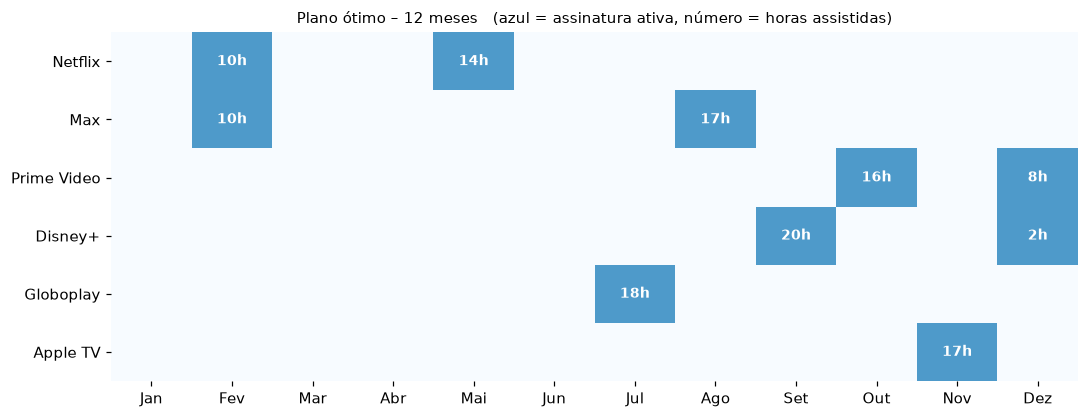

In [8]:
res = resolver(titulos, ofertas, meses, H)
mostrar(res, titulos, ofertas, meses)
calendario(res, titulos, ofertas, meses, PLATAFORMAS, "Plano ótimo – 12 meses")

### 3.4 Quanto economizamos?

Comparamos o plano ótimo com três estratégias:

1. **Assinar tudo o ano inteiro** (sempre pela combinação mais barata que cubra as 6 plataformas).
2. **Ingênua – "ver assim que lançar":** cada título vai para o primeiro mês em que está disponível e cabe nas horas, e paga-se o mais barato para cada mês.
3. **Ótimo sem anúncios:** o mesmo modelo, proibindo os planos com anúncios (para quem não aguenta propaganda).

Estratégia,Custo no ano (R$),Economia vs. assinar tudo
Assinar tudo o ano inteiro,R$ 1530.00,0%
Ingênua (ver assim que lançar),R$ 335.50,78%
Ótimo sem anúncios,R$ 305.10,80%
Ótimo (com anúncios),R$ 222.00,85%


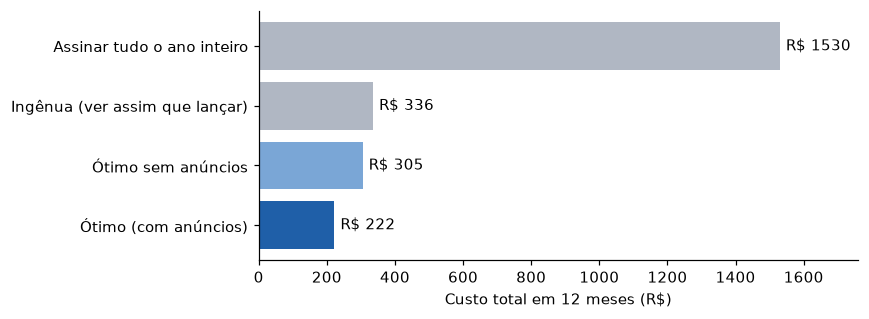

In [9]:
cob = construir_cobertura(ofertas)

custo_tudo   = cob(frozenset(PLATAFORMAS)) * 12
custo_naive  = baseline_ingenuo(titulos, ofertas, meses, H)
custo_otimo  = res["custo"]
res_sem_ads  = resolver(titulos, ofertas[~ofertas["anuncios"]], meses, H)
custo_sem_ads = res_sem_ads["custo"]

tabela = pd.DataFrame({
    "Estratégia": ["Assinar tudo o ano inteiro", "Ingênua (ver assim que lançar)", "Ótimo sem anúncios", "Ótimo (com anúncios)"],
    "Custo no ano (R$)": [custo_tudo, custo_naive, custo_sem_ads, custo_otimo],
})
tabela["Economia vs. assinar tudo"] = (1 - tabela["Custo no ano (R$)"] / custo_tudo).map("{:.0%}".format)
display(tabela.style.format({"Custo no ano (R$)": "R$ {:.2f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 3))
cores = ["#b0b7c3", "#b0b7c3", "#7aa6d6", "#1f5fa8"]
barras = ax.barh(tabela["Estratégia"][::-1], tabela["Custo no ano (R$)"][::-1], color=cores[::-1])
ax.bar_label(barras, fmt="R$ %.0f", padding=4)
ax.set_xlabel("Custo total em 12 meses (R$)"); ax.set_xlim(0, custo_tudo * 1.15)
plt.tight_layout(); plt.show()

## 4. Entendendo o resultado

### 4.1 Por que precisamos de variáveis inteiras? (relaxamento linear)
Se deixássemos os $y$ serem frações entre 0 e 1, o solver poderia "assinar 30% da Netflix", pagando 30% do preço. Isso dá um custo **menor que o real**, ou seja, um limite inferior (*lower bound*). A diferença para o ótimo inteiro é o *gap* de integralidade.

In [10]:
res_lp = resolver(titulos, ofertas, meses, H, relaxar=True, cortes=False)
print(f"Relaxamento linear (limite inferior): R$ {res_lp['custo']:.2f}")
print(f"Ótimo inteiro:                         R$ {res['custo']:.2f}")
print(f"Gap de integralidade: {100 * (res['custo'] - res_lp['custo']) / res['custo']:.1f}%")

Relaxamento linear (limite inferior): R$ 128.72
Ótimo inteiro:                         R$ 222.00
Gap de integralidade: 42.0%


Esse gap é grande, e é por isso que o problema não é "só um LP": quanto maior o gap, mais o solver precisa explorar combinações para provar que achou o melhor. Dois remédios:

1. **Escrever a restrição de ligação para cada par $(t,m)$** (como fizemos), que é mais forte que somar tudo numa só (Wolsey, 1998).
2. **Cortes de capacidade (argumento de empacotamento).** Se uma plataforma $p$ tem $h_p$ horas de títulos exclusivos e só dá para ver $H$ horas por mês, então $p$ precisa estar ativa em pelo menos $\lceil h_p/H \rceil$ meses:
$$\sum_{m}\sum_{k \ni p} y_{k,m} \;\ge\; \Big\lceil h_p / H \Big\rceil .$$
Todo plano viável já cumpre isso (o corte não elimina nenhuma solução inteira), então o **ótimo não muda**, mas o solver descarta ramos muito mais cedo. Aqui, resolver com $H=20$ passa de mais de 20 s (sem conseguir provar o ótimo) para menos de 1 s. O parâmetro `cortes=True` do `resolver` liga isso; o resultado é o mesmo com `cortes=False`, só mais lento (conferido na célula abaixo).

In [11]:
# Os cortes só aceleram: o ótimo tem de ser idêntico com e sem eles (conferência no exemplo pequeno e no completo para H = 25)
for nome, (tt, oo, hh) in {"pequeno": (titulos_peq, ofertas_peq, 20), "completo (H=25)": (titulos, ofertas, 25)}.items():
    a = resolver(tt, oo, meses_peq if nome == "pequeno" else meses, hh, cortes=True)["custo"]
    b = resolver(tt, oo, meses_peq if nome == "pequeno" else meses, hh, cortes=False)["custo"]
    print(f"{nome:>16}: com cortes R$ {a:.2f} | sem cortes R$ {b:.2f}")
    assert abs(a - b) < 1e-6

         pequeno: com cortes R$ 139.60 | sem cortes R$ 139.60


 completo (H=25): com cortes R$ 153.30 | sem cortes R$ 153.30


### 4.2 Sensibilidade ao limite de horas
O que acontece com o custo se eu tiver mais ou menos tempo livre por mês?

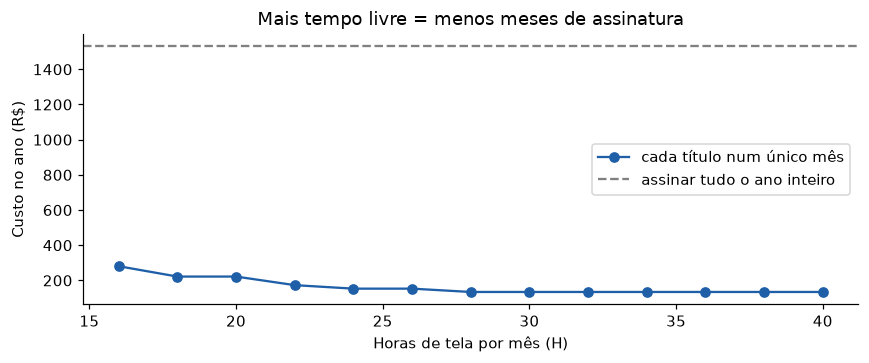

Horas totais da lista: 132 → abaixo de 11 h/mês é impossível ver tudo em 12 meses.


In [12]:
Hs = list(range(12, 41, 2))
custos_int = [(lambda r: r["custo"] if r else np.nan)(resolver(titulos, ofertas, meses, h)) for h in Hs]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(Hs, custos_int, "o-", color="#1f5fa8", label="cada título num único mês")
ax.axhline(custo_tudo, color="gray", ls="--", label="assinar tudo o ano inteiro")
ax.set_xlabel("Horas de tela por mês (H)"); ax.set_ylabel("Custo no ano (R$)")
ax.set_title("Mais tempo livre = menos meses de assinatura"); ax.legend()
plt.tight_layout(); plt.show()
print("Horas totais da lista:", titulos["horas"].sum(), "→ abaixo de", int(np.ceil(titulos["horas"].sum() / 12)), "h/mês é impossível ver tudo em 12 meses.")

## 5. Discussão

### 5.1 Variação: dividir um título entre meses
Até aqui cada título é visto inteiro num único mês. Se pudermos ver parte num mês e o resto em outro (a série é longa, afinal), o modelo fica mais flexível: basta deixar $x_{t,m}\in[0,1]$ (contínuo), com $\sum_m x_{t,m}=1$ e a fração $x_{t,m}$ dizendo quanto do título vemos no mês $m$. Só os $y$ continuam binários.

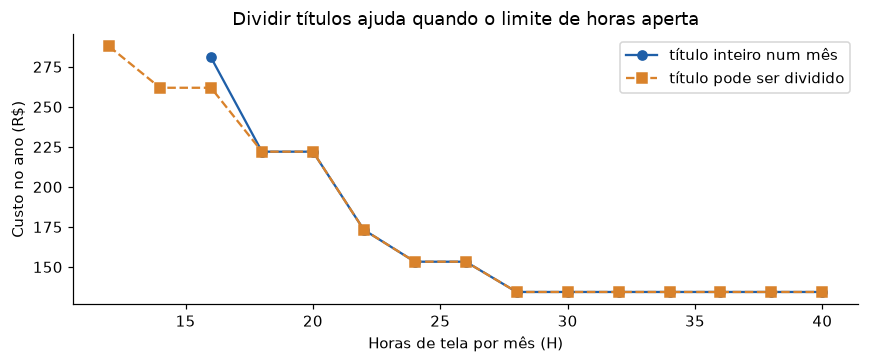

Com H = 20h: título inteiro R$ 222.00  |  título dividido R$ 222.00


In [13]:
Hs2 = list(range(12, 41, 2))
custos_div = [(lambda r: r["custo"] if r else np.nan)(resolver(titulos, ofertas, meses, h, dividir=True)) for h in Hs2]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(Hs, custos_int, "o-", color="#1f5fa8", label="título inteiro num mês")
ax.plot(Hs2, custos_div, "s--", color="#d9822b", label="título pode ser dividido")
ax.set_xlabel("Horas de tela por mês (H)"); ax.set_ylabel("Custo no ano (R$)")
ax.set_title("Dividir títulos ajuda quando o limite de horas aperta"); ax.legend()
plt.tight_layout(); plt.show()

r_div = resolver(titulos, ofertas, meses, H, dividir=True)
print(f"Com H = {H}h: título inteiro R$ {res['custo']:.2f}  |  título dividido R$ {r_div['custo']:.2f}")

### 5.2 Variação: dividir as contas com amigos
Se três pessoas com listas diferentes dividem as assinaturas, o custo de cada oferta $k$ é pago **uma vez** e rateado, mas cada pessoa tem o seu próprio limite de horas e a sua própria lista. No modelo, só mudam duas coisas: os títulos ganham um "dono" e a restrição de horas passa a valer **por pessoa e por mês**. As assinaturas $y$ continuam compartilhadas.

In [14]:
listas = {
    "Eu":  ["Stranger Things T5", "Adolescence", "The Last of Us T2", "Succession T4", "The Boys T5",
            "Fallout T2", "Andor T2", "The Mandalorian T3", "Severance T2", "Ted Lasso T3",
            "Filme Oscar", "Minissérie Globoplay"],
    "Bia": ["Stranger Things T5", "Wednesday T2", "The Last of Us T2", "House of the Dragon T2",
            "The Boys T5", "Fallout T2", "Filme Oscar", "Ted Lasso T3"],
    "Caio": ["Andor T2", "The Mandalorian T3", "Succession T4", "Reacher T3", "The Boys T5",
             "Reality Globoplay", "Minissérie Globoplay", "Filme Pixar"],
}
grupo = pd.concat([titulos[titulos["nome"].isin(l)].assign(quem=p) for p, l in listas.items()], ignore_index=True)

# Cada um sozinho
sozinho = {p: resolver(grupo[grupo["quem"] == p], ofertas, meses, H)["custo"] for p in listas}
# Todos juntos, assinaturas compartilhadas
junto = resolver(grupo, ofertas, meses, H)
rateio = junto["custo"] / len(listas)

comp = pd.DataFrame({"Sozinho (R$)": sozinho, "Dividindo (R$)": {p: rateio for p in listas}})
comp["Economia"] = (1 - comp["Dividindo (R$)"] / comp["Sozinho (R$)"]).map("{:.0%}".format)
display(comp.style.format({"Sozinho (R$)": "{:.2f}", "Dividindo (R$)": "{:.2f}"}))
print(f"Soma dos custos individuais: R$ {sum(sozinho.values()):.2f}  |  custo do grupo: R$ {junto['custo']:.2f}")
assert junto["custo"] <= sum(sozinho.values()) + 1e-6   # juntar nunca piora

,Sozinho (R$),Dividindo (R$),Economia
Eu,134.40,54.10,60%
Bia,81.60,54.10,34%
Caio,119.50,54.10,55%


Soma dos custos individuais: R$ 335.50  |  custo do grupo: R$ 162.30


A divisão **igual** do custo é só uma regra simples. Repare que ela não é necessariamente justa (quem tem a lista mais "exclusiva" acaba sustentando assinaturas que os outros também usam). Rateios proporcionais às horas ou ao custo marginal de cada pessoa seriam alternativas.

Por que **juntar nunca piora**? Qualquer plano individual continua viável no problema do grupo (basta a união das assinaturas), então o ótimo do grupo é no máximo a soma dos ótimos individuais. Na prática, o ganho depende da **sobreposição das listas**: quanto mais títulos em comum, mais as pessoas aproveitam a mesma assinatura.

### 5.3 Limitações
- **Dados:** os preços mudam, o catálogo muda, e um título pode sair antes do previsto. O modelo é tão bom quanto o dado.
- **Telas simultâneas:** o compartilhamento assume que os planos aguentam várias pessoas assistindo ao mesmo tempo, e algumas plataformas restringem contas compartilhadas fora da mesma casa.
- **Anúncios e qualidade:** tratamos o plano com anúncios como equivalente ao outro, só mais barato. Podemos medir o "incômodo" como um custo $\lambda$ por hora de anúncio.
- **Sem custos de troca:** ignoramos o trabalho de cancelar/reassinar e eventuais cobranças proporcionais.
- **Todo título tem a mesma "urgência":** ver *The Boys* só em dezembro, por causa do spoiler, tem custo que o modelo não vê.
- **Tamanho:** a cobertura de conjuntos é NP-difícil. Para listas de dezenas de títulos o solver resolve na hora, mas listas com milhares de itens exigiriam outras técnicas.

### 5.4 Extensões possíveis
1. **Planos anuais e fidelidade:** acrescentar ofertas que duram 12 meses com desconto, que viram uma variável binária única em vez de uma por mês.
2. **Preferência de ordem:** exigir que a temporada 2 seja vista depois da temporada 1 (restrições de precedência entre os $x$).
3. **Custo de espera:** penalizar assistir muito tempo depois da estreia (spoilers), com um termo $\sum_t \beta\,(m-a_t)\,x_{t,m}$ no objetivo.
4. **Incerteza:** otimização robusta ou estocástica para preços e lançamentos que podem atrasar.
5. **Mais de uma pessoa no mesmo plano com limite de telas:** modelar o número de telas simultâneas.

### 5.5 Conclusão
Em um problema de uso cotidiano, juntamos **cobertura de conjuntos**, **custo fixo** e **restrição de capacidade** em um único MILP pequeno. Ele foi verificado por força bruta no exemplo pequeno e escalou sem esforço para 12 meses, 12 ofertas e 17 títulos. A economia vem de duas fontes: **concentrar** os títulos de uma plataforma nos poucos meses em que ela é assinada (é aqui que o limite de horas faz a diferença) e **escolher** a combinação mais barata de planos e combos em cada mês.

## Referências

- Chvátal, V. (1979). A greedy heuristic for the set-covering problem. *Mathematics of Operations Research*, 4(3), 233–235.
- Hirsch, W. M., & Dantzig, G. B. (1968). The fixed charge problem. *Naval Research Logistics Quarterly*, 15(3), 413–424.
- Hoffman, K. L., & Padberg, M. (1993). Solving airline crew scheduling problems by branch-and-cut. *Management Science*, 39(6), 657–682.
- Huangfu, Q., & Hall, J. A. J. (2018). Parallelizing the dual revised simplex method. *Mathematical Programming Computation*, 10, 119–142. (solver HiGHS)
- Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations*, Plenum Press, 85–103.
- Toregas, C., Swain, R., ReVelle, C., & Bergman, L. (1971). The location of emergency service facilities. *Operations Research*, 19(6), 1363–1373.
- Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.
- Wolsey, L. A. (1998). *Integer Programming*. Wiley.
- Disponibilidade de títulos: JustWatch (https://www.justwatch.com/br). Preços: sites oficiais de cada plataforma (conferir na data da apresentação).
- Material da disciplina COS360/COM361: aula 19 (custo fixo) e aula 21 (cobertura de conjuntos).